In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["Target"] = iris.target

print("Original Dataset:")
display(df.head())

print("Dataset Shape:", df.shape)

Original Dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Dataset Shape: (150, 5)


In [3]:
X = df.drop("Target", axis=1)
y = df["Target"]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (150, 4)
Target Shape: (150,)


In [4]:
print("Number of Features:", X.shape[1])
print("Number of Records:", X.shape[0])

Number of Features: 4
Number of Records: 150


In [5]:
print("Dataset Dimensions:")
print("Rows:", X.shape[0])
print("Columns:", X.shape[1])

print("\nFeature Names:")
print(X.columns.tolist())

Dataset Dimensions:
Rows: 150
Columns: 4

Feature Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [6]:
feature_dimensions = [2, 4, 8, 16, 32, 64, 128]

dimension_analysis = pd.DataFrame({
    "Number_of_Features": feature_dimensions,
    "Complexity_Level": [
        "Low", "Low", "Moderate", "Moderate",
        "High", "Very High", "Very High"
    ]
})

display(dimension_analysis)

,Number_of_Features,Complexity_Level
0,2,Low
1,4,Low
2,8,Moderate
3,16,Moderate
4,32,High
5,64,Very High
6,128,Very High


In [7]:
print("Original Feature Count:", X.shape[1])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X_scaled)

print("Reduced Feature Count:", X_reduced.shape[1])

Original Feature Count: 4
Reduced Feature Count: 2


In [8]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

print("PCA Transformed Dataset:")
display(pca_df.head())

PCA Transformed Dataset:


,PC1,PC2
0,-2.264703,0.480027
1,-2.080961,-0.674134
2,-2.364229,-0.341908
3,-2.299384,-0.597395
4,-2.389842,0.646835


In [9]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Principal Components:")
print("PC1:", X_pca[:, 0][:5])
print("PC2:", X_pca[:, 1][:5])

display(pd.DataFrame(X_pca, columns=["PC1", "PC2"]).head())

Principal Components:
PC1: [-2.26470281 -2.08096115 -2.36422905 -2.29938422 -2.38984217]
PC2: [ 0.4800266  -0.67413356 -0.34190802 -0.59739451  0.64683538]


,PC1,PC2
0,-2.264703,0.480027
1,-2.080961,-0.674134
2,-2.364229,-0.341908
3,-2.299384,-0.597395
4,-2.389842,0.646835


In [10]:
explained_variance = pca.explained_variance_ratio_

variance_df = pd.DataFrame({
    "Principal_Component": ["PC1", "PC2"],
    "Explained_Variance": explained_variance
})

variance_df["Percentage"] = (
    variance_df["Explained_Variance"] * 100
)

print("Explained Variance:")
display(variance_df)

print(
    "Total Variance Retained:",
    round(explained_variance.sum() * 100, 2),
    "%"
)

Explained Variance:


,Principal_Component,Explained_Variance,Percentage
0,PC1,0.729624,72.962445
1,PC2,0.228508,22.850762


Total Variance Retained: 95.81 %


In [11]:
eigenvectors = pca.components_

eigenvector_df = pd.DataFrame(
    eigenvectors,
    columns=X.columns,
    index=["PC1", "PC2"]
)

print("PCA Eigenvectors / Component Loadings:")
display(eigenvector_df)

PCA Eigenvectors / Component Loadings:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
PC1,0.521066,-0.269347,0.580413,0.564857
PC2,0.377418,0.923296,0.024492,0.066942


In [12]:
eigenvalues = pca.explained_variance_

eigenvalue_df = pd.DataFrame({
    "Principal_Component": ["PC1", "PC2"],
    "Eigenvalue": eigenvalues
})

print("Eigenvalues:")
display(eigenvalue_df)

Eigenvalues:


,Principal_Component,Eigenvalue
0,PC1,2.938085
1,PC2,0.920165


In [13]:
pca_result = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_result["Target"] = y.values

print("Original Dataset Shape:", X.shape)
print("Transformed Dataset Shape:", pca_result[["PC1", "PC2"]].shape)

display(pca_result.head())

Original Dataset Shape: (150, 4)
Transformed Dataset Shape: (150, 2)


,PC1,PC2,Target
0,-2.264703,0.480027,0
1,-2.080961,-0.674134,0
2,-2.364229,-0.341908,0
3,-2.299384,-0.597395,0
4,-2.389842,0.646835,0


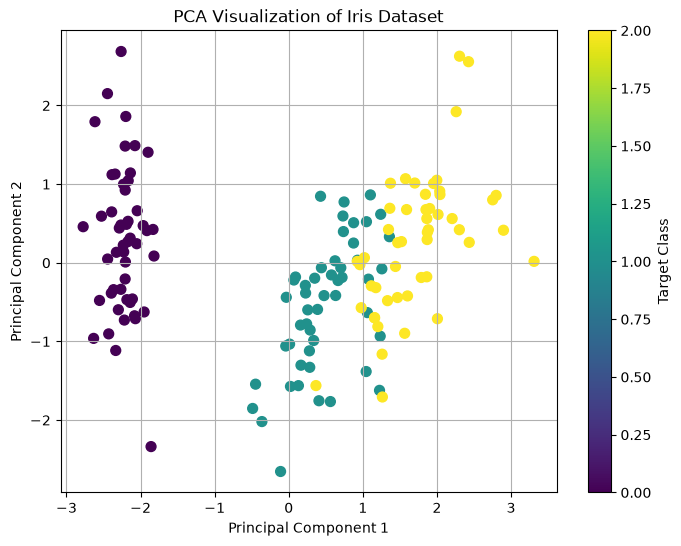

In [14]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    pca_result["PC1"],
    pca_result["PC2"],
    c=pca_result["Target"],
    cmap="viridis",
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Iris Dataset")

plt.colorbar(scatter, label="Target Class")
plt.grid(True)
plt.show()

In [15]:
advantages = [
    "Reduces dimensionality",
    "Removes redundant information",
    "Supports data visualization",
    "Can reduce noise",
    "Improves computational efficiency"
]

for advantage in advantages:
    print("-", advantage)

- Reduces dimensionality
- Removes redundant information
- Supports data visualization
- Can reduce noise
- Improves computational efficiency


In [16]:
limitations = [
    "Difficult to interpret components",
    "Possible information loss",
    "Limited to linear transformations",
    "Sensitive to outliers",
    "Requires numerical features"
]

for limitation in limitations:
    print("-", limitation)

- Difficult to interpret components
- Possible information loss
- Limited to linear transformations
- Sensitive to outliers
- Requires numerical features


In [17]:
use_cases = pd.DataFrame({
    "Scenario": [
        "High-dimensional dataset",
        "Highly correlated features",
        "Data visualization",
        "Computational efficiency"
    ],
    "PCA_Useful": ["Yes", "Yes", "Yes", "Yes"]
})

display(use_cases)

,Scenario,PCA_Useful
0,High-dimensional dataset,Yes
1,Highly correlated features,Yes
2,Data visualization,Yes
3,Computational efficiency,Yes


In [18]:
not_use_cases = pd.DataFrame({
    "Scenario": [
        "Need original feature interpretation",
        "Mostly categorical data",
        "Information loss is unacceptable",
        "Strong nonlinear patterns"
    ],
    "PCA_Recommended": ["No", "Usually No", "No", "Consider alternatives"]
})

display(not_use_cases)

,Scenario,PCA_Recommended
0,Need original feature interpretation,No
1,Mostly categorical data,Usually No
2,Information loss is unacceptable,No
3,Strong nonlinear patterns,Consider alternatives


In [19]:
# Standardize the original features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA
pca_final = PCA(n_components=2)
X_final = pca_final.fit_transform(X_scaled)

# Create final DataFrame
final_pca_df = pd.DataFrame(
    X_final,
    columns=["Principal_Component_1", "Principal_Component_2"]
)

final_pca_df["Target"] = y.values

print("Original Dataset Shape:", X.shape)
print("Reduced Dataset Shape:", final_pca_df.shape)

print("\nExplained Variance Ratio:")
print(pca_final.explained_variance_ratio_)

print(
    "\nTotal Variance Retained:",
    round(pca_final.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

display(final_pca_df.head(10))

Original Dataset Shape: (150, 4)
Reduced Dataset Shape: (150, 3)

Explained Variance Ratio:
[0.72962445 0.22850762]

Total Variance Retained: 95.81 %


,Principal_Component_1,Principal_Component_2,Target
0,-2.264703,0.480027,0
1,-2.080961,-0.674134,0
2,-2.364229,-0.341908,0
3,-2.299384,-0.597395,0
4,-2.389842,0.646835,0
5,-2.075631,1.489178,0
6,-2.444029,0.047644,0
7,-2.232847,0.223148,0
8,-2.334640,-1.115328,0
9,-2.184328,-0.469014,0


In [20]:
pca_summary = pd.DataFrame({
    "Concept": [
        "Dimensionality",
        "High-Dimensional Data",
        "Curse of Dimensionality",
        "PCA",
        "Principal Components",
        "Explained Variance",
        "Eigenvectors",
        "Eigenvalues",
        "PCA Transformation",
        "PCA Visualization"
    ],
    "Description": [
        "Number of features in a dataset",
        "Dataset containing many features",
        "Problems caused by increasing dimensions",
        "Principal Component Analysis",
        "New variables created by PCA",
        "Variance captured by components",
        "Directions of principal components",
        "Variance represented by components",
        "Converts original features into components",
        "Displays reduced data in two dimensions"
    ]
})

display(pca_summary)

,Concept,Description
0,Dimensionality,Number of features in a dataset
1,High-Dimensional Data,Dataset containing many features
2,Curse of Dimensionality,Problems caused by increasing dimensions
3,PCA,Principal Component Analysis
4,Principal Components,New variables created by PCA
5,Explained Variance,Variance captured by components
6,Eigenvectors,Directions of principal components
7,Eigenvalues,Variance represented by components
8,PCA Transformation,Converts original features into components
9,PCA Visualization,Displays reduced data in two dimensions
